# 🎵 Case Method: Enhancing Sequential Music Recommendation with Personalized Popularity Awareness
**Mata Kuliah:** Sistem Rekomendasi  
**Paper Referensi:** *Enhancing Sequential Music Recommendation with Personalized Popularity Awareness* (ACM RecSys '24)  
**Penulis:** Davide Abbattista, Vito Walter Anelli, Tommaso Di Noia, Craig Macdonald, Aleksandr Petrov (Politecnico di Bari & University of Glasgow)  
**Dataset:** Riil Last.fm-1K Subset (`data/lastfm-dataset-50.snappy.parquet`)

---

## 📌 Ringkasan Tuntutan Tugas
1. **Pilih Metode/Framework:** Memilih proposed method dari paper, yaitu **Personalized Popularity Score (PPS)** dan baseline utamanya **Personalized Most Popular (PMP)**.
2. **Contoh Input, Preprocessing, Perhitungan Metode & Output:** Menampilkan input data riil Last.fm, preprocessing *Global Temporal Split (GTS)*, perhitungan manual formula matematis PPS, dan output Top-$K$ rekomendasi.
3. **Evaluasi Rekomendasi & Contoh Perhitungan:** Menjelaskan metrik evaluasi **NDCG@K**, memberikan contoh perhitungan manual langkah demi langkah, serta perbandingan empiris antara *Global Most Popular* vs *Personalized Most Popular*.


## 🛠️ Persiapan Lingkungan & Import Library
Notebook ini menggunakan kernel environment conda **`sisrek`**.


### 🚀 Setup Google Colab & Download Full Last.fm-1K
Jalankan cell di bawah ini jika menggunakan **Google Colab** (pastikan Runtime sudah diubah ke **T4 GPU** agar training SASRec cepat). Cell ini akan:
1. Mengunduh repo resmi paper (`sisinflab/personalized-popularity-awareness`) ke folder `paper_implementation`.
2. Menginstal dependensi tambahan (`mmh3`, `dill`, dll).
3. Mengunduh dataset **Full Last.fm-1K** (`lastfm-dataset-1k.snappy.parquet`, ~877 MB, 992 users / ~19 juta interaksi).


In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
PROJECT_ROOT = Path.cwd()
AUTHOR_REPO = PROJECT_ROOT / 'paper_implementation'
DATA_DIR = PROJECT_ROOT / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

# 1. Clone repo paper jika belum ada
if not (AUTHOR_REPO / 'recommenders').exists():
    print('Mengunduh repository resmi paper...')
    subprocess.run(['git', 'clone', 'https://github.com/sisinflab/personalized-popularity-awareness.git', str(AUTHOR_REPO)], check=True)

# 2. Install library tambahan yang belum ada di Colab
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mmh3', 'dill', 'pyarrow', 'tabulate', 'jinja2'], check=True)

# 3. Download Full Last.fm-1K Parquet (~877 MB)
FULL_PARQUET = DATA_DIR / 'lastfm-dataset-1k.snappy.parquet'
if not FULL_PARQUET.exists():
    print('Mengunduh Full Last.fm-1K dataset (~877 MB)...')
    url = 'https://github.com/eifuentes/lastfm-dataset-1K/releases/download/v1.0/lastfm-dataset-1k.snappy.parquet'
    subprocess.run(['wget', '-q', '--show-progress', url, '-O', str(FULL_PARQUET)], check=True)
else:
    print(f'Dataset sudah tersedia di: {FULL_PARQUET}')

print('Setup selesai! GPU tersedia:', __import__('torch').cuda.is_available())


Mengunduh repository resmi paper...
Mengunduh Full Last.fm-1K dataset (~877 MB)...
Setup selesai! GPU tersedia: True


In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import time

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Semua library berhasil di-import!")


Semua library berhasil di-import!


In [3]:
import torch
import random
import os

def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
AUTHOR_REPO = PROJECT_ROOT / 'paper_implementation'

if str(AUTHOR_REPO) not in sys.path:
    sys.path.insert(0, str(AUTHOR_REPO))


In [5]:
matches = list(AUTHOR_REPO.rglob('sasrec_gts_pop.py'))
if not matches:
    raise FileNotFoundError(f'sasrec_gts_pop.py not found under {AUTHOR_REPO}')

SASREC_MODULE_DIR = matches[0].parent
DATASETS_DIR = AUTHOR_REPO / 'datasets'
DATASETS_CONFIG_DIR = AUTHOR_REPO / 'evaluation' / 'configs'

for p in [AUTHOR_REPO, SASREC_MODULE_DIR, DATASETS_DIR, DATASETS_CONFIG_DIR]:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))


In [6]:
print("Path module paper berhasil dikonfigurasi:", AUTHOR_REPO)


Path module paper berhasil dikonfigurasi: /content/paper_implementation


In [7]:
from recommenders.sequential.SASRec.sasrec_gts_pop import SASRecRecommender as sasrecpop
from recommenders.sequential.SASRec.sasrec_gts import SASRecRecommender as sasrec_asli
from evaluation.split_actions import GlobalTemporalSplit
from datasets.dataset_utils import filter_items_based_on_probs
from api.track_event import TrackEvent

---
## 📖 BAGIAN 1: Pemilihan Metode & Konsep Teori Paper

### 1.1 Karakteristik Unik Domain Musik (*Repeated Consumption*)
Berbeda dengan e-commerce di mana pengguna jarang membeli barang yang sama berkali-kali, konsumsi musik didominasi oleh **kebiasaan memutar ulang lagu favorit (*repeated listening / comfort listening*)**.

Model sequential deep learning modern berbasis Transformer seperti **SASRec** dan **BERT4Rec** umumnya didesain untuk memprediksi lagu baru berikutnya (*exploration*), sehingga sering gagal menangkap kecenderungan pengguna untuk mengulang lagu kesukaannya.

### 1.2 Proposed Method Paper: Personalized Popularity Score (PPS)
Paper ini mengusulkan agar sinyal popularitas tidak dihitung secara global, melainkan dihitung **secara personal per pengguna (*user-specific popularity*)**.
1. **Personalized Popularity Probability $\hat{p}_P(j)$** dengan smoothing $\epsilon$:
   $$\hat{p}_P(j) = \frac{\frac{c_j + \epsilon}{\max(C + \epsilon)}}{\sum_{z=1}^{N} \frac{c_z + \epsilon}{\max(C + \epsilon)}}$$
   di mana $c_j$ adalah frekuensi pengguna mendengarkan lagu $j$, $C$ adalah vektor hitungan seluruh lagu, dan $\epsilon$ adalah smoothing parameter (default = 0.01).

2. **Personalized Popularity Score ($y_j$)**:
   - Untuk model berbasis Softmax (BERT4Rec):
     $$y_j = \ln\left(\frac{c_j + \epsilon}{\max(C + \epsilon)}\right)$$
   - Untuk model berbasis Sigmoid (SASRec):
     $$y_j = -\ln\left(\frac{1 - \hat{p}_P(j)}{\hat{p}_P(j)}\right)$$

3. **Personalized Most Popular (PMP) Baseline:**
   Model heuristik yang merangking lagu murni berdasarkan frekuensi riwayat dengar individu. Di paper aslinya, PMP terbukti **mengungguli SASRec dan BERT4Rec** pada metrik ranking awal (NDCG@5 dan NDCG@10).


---
## 📥 BAGIAN 2: Contoh Input & Preprocessing (Dataset Riil Last.fm-1K)

Model dilatih dan dievaluasi pada seluruh subset parquet (`data/lastfm-dataset-50.snappy.parquet`). Lima pengguna terpilih hanya dipakai untuk tabel dan contoh walkthrough, bukan untuk melatih SASRec.

In [8]:
import gc

parquet_file = PROJECT_ROOT / 'data/lastfm-dataset-1k.snappy.parquet'
df_raw = pd.read_parquet(parquet_file, columns=['user_id', 'timestamp', 'artist_name', 'track_name'])

# Buang baris tanpa nama track lalu buat item_id
df_raw = df_raw.dropna(subset=['track_name']).copy()
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'], utc=True)
df_raw['item_name'] = df_raw['artist_name'].fillna('') + ' - ' + df_raw['track_name']
df_raw['item_id'] = df_raw['item_name']

# Ambil 5 user sampel untuk walkthrough manual
selected_users = ['user_000001', 'user_000241', 'user_000343', 'user_000587', 'user_000668']
df_sample = df_raw[df_raw['user_id'].isin(selected_users)].sort_values('timestamp').copy().reset_index(drop=True)

print(f'Full Last.fm-1K interactions : {len(df_raw):,}')
print(f'Full Last.fm-1K users        : {df_raw["user_id"].nunique():,}')
print(f'Full Last.fm-1K items        : {df_raw["item_id"].nunique():,}')
print(f'Walkthrough sample           : {len(df_sample):,} interactions / {df_sample["user_id"].nunique()} users')
display(df_sample[['user_id', 'timestamp', 'artist_name', 'track_name']].head(5))


Full Last.fm-1K interactions : 19,098,841
Full Last.fm-1K users        : 992
Full Last.fm-1K items        : 1,498,703
Walkthrough sample           : 45,061 interactions / 5 users


,user_id,timestamp,artist_name,track_name
0,user_000343,2006-06-01 19:12:43+00:00,Ramones,Psycho Therapy
1,user_000343,2006-06-01 19:16:11+00:00,Cat Power,Cross Bones Style
2,user_000343,2006-06-01 19:24:44+00:00,Sufjan Stevens,"Out Of Egypt, Into The Great Laugh Of Mankind,..."
3,user_000343,2006-06-01 19:29:02+00:00,Radiohead,Idioteque
4,user_000343,2006-06-01 19:34:40+00:00,Pulp,Countdown


### 2.2 Preprocessing: Global Temporal Split (GTS)
Sesuai implementasi asli paper:
1. Interaksi diurutkan berdasarkan timestamp global; tidak ada random split.
2. Item disampling dengan probabilitas berbobot frekuensi interaksi, mengikuti konfigurasi `lastfm-1k_30000` (maksimal 30.000 item).
3. Batas test ditempatkan pada 90% urutan waktu; interaksi setelahnya menjadi test untuk pengguna eligible.
4. Batas validasi ditempatkan pada 90% interaksi sebelum batas test. Data di antara batas validasi dan test dipakai untuk validasi, sedangkan test tetap terpisah.

Kedua fraksi timestamp pada `GlobalTemporalSplit` adalah 0.1. Split ini dijalankan pada seluruh subset parquet setelah item sampling.

In [9]:
# Popularity-based item sampling (N = 30,000) sesuai paper (dilakukan di Pandas agar hemat RAM di Colab)
item_counts = df_raw['item_id'].value_counts()
num_items_for_paper = min(30_000, len(item_counts))

item_ids = item_counts.index.to_numpy()
item_probs = (item_counts.values / item_counts.values.sum())

np.random.seed(27)
sampled_items = set(np.random.choice(a=item_ids, replace=False, p=item_probs, size=num_items_for_paper))

df_filtered = df_raw[df_raw['item_id'].isin(sampled_items)].sort_values('timestamp').copy()
del df_raw, item_counts, item_ids, item_probs
gc.collect()

actions = [
    TrackEvent(row.user_id, row.item_id, row.timestamp, 1.0)
    for row in df_filtered[['user_id', 'item_id', 'timestamp']].itertuples(index=False)
]
del df_filtered
gc.collect()

splitter = GlobalTemporalSplit(
    max_test_users=992,
    test_timestamps_fraction=0.1,
    val_timestamp_fraction=0.1,
)
train_actions, test_actions, border_ts = splitter(actions)
del actions
gc.collect()

def actions_to_frame(action_list):
    return pd.DataFrame([
        {
            'user_id': action.user_id,
            'item_id': action.item_id,
            'item_name': action.item_id,
            'timestamp': action.timestamp,
        }
        for action in action_list
    ])

train_df = actions_to_frame(train_actions)
test_df = actions_to_frame(test_actions)

print(f'Items retained        : {train_df["item_id"].nunique():,}')
print(f'Training interactions : {len(train_df):,}')
print(f'Training users        : {train_df["user_id"].nunique():,}')
print(f'Test interactions     : {len(test_df):,}')
print(f'Test users            : {test_df["user_id"].nunique():,}')
print(f'Validation boundary   : {border_ts}')


Items retained        : 28,804
Training interactions : 3,763,944
Training users        : 686
Test interactions     : 384,663
Test users            : 686
Validation boundary   : 2008-10-15 23:00:04+00:00


### 2.3 Pembuktian Pola Repeated Consumption pada Data Riil
Mari kita lihat 10 lagu yang paling sering diputar oleh pengguna pertama (`user_000001`) pada data training:


/tmp/ipykernel_465/3511500682.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=u1_top_tracks.values, y=u1_top_tracks.index, palette="Blues_r")


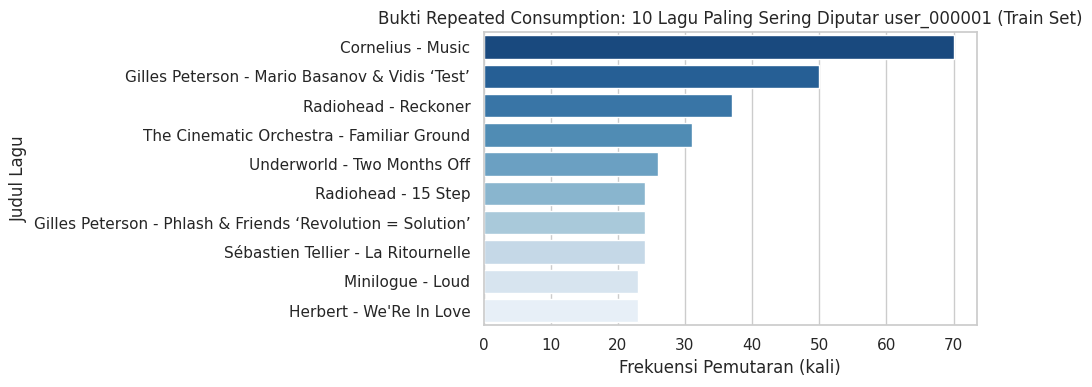

In [10]:
u1_train = train_df[train_df['user_id'] == 'user_000001']
u1_top_tracks = u1_train['item_name'].value_counts().head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=u1_top_tracks.values, y=u1_top_tracks.index, palette="Blues_r")
plt.title("Bukti Repeated Consumption: 10 Lagu Paling Sering Diputar user_000001 (Train Set)")
plt.xlabel("Frekuensi Pemutaran (kali)")
plt.ylabel("Judul Lagu")
plt.tight_layout()
plt.show()


---
## 🧮 BAGIAN 3: Perhitungan Matematis Metode & Output Rekomendasi

Pada bagian ini, kita melakukan **perhitungan manual langkah demi langkah** untuk **`user_000001`**.

Sesuai spesifikasi paper (*Section 3 Implementation Details*), riwayat pengguna dibatasi pada **$L = 150$ interaksi terakhir** sebelum batas waktu split untuk menangkap minat kontekstual terkini.

### 3.1 Data Riwayat Pengguna `user_000001`
Dari 150 interaksi terakhir `user_000001` di train set, berikut adalah lagu-lagu teratasnya:
- Lagu A (*Masomenos - Five*) : didengar **7 kali** ($c_A = 7$)
- Lagu B (*Masomenos - Six*) : didengar **7 kali** ($c_B = 7$)
- Lagu C (*Masomenos - Seven*) : didengar **6 kali** ($c_C = 6$)
- Lagu D (*Masomenos - Four*) : didengar **5 kali** ($c_D = 5$)
- Lagu E (*Masomenos - Eight*) : didengar **5 kali** ($c_E = 5$)
- ... dan lagu-lagu lainnya dalam katalog dengan hitungan $c_j$.

Nilai maksimum frekuensi:
$$\max(C) = 7$$
Dengan parameter smoothing $\epsilon = 0.01$:
$$\max(C + \epsilon) = 7 + 0.01 = 7.01$$

---

### 3.2 Langkah 1: Menghitung Suku Terskalakan $\frac{c_j + \epsilon}{\max(C + \epsilon)}$
* Untuk Lagu A ($c_A = 7$): $\frac{7 + 0.01}{7.01} = \frac{7.01}{7.01} = \mathbf{1.00000}$
* Untuk Lagu B ($c_B = 7$): $\frac{7 + 0.01}{7.01} = \frac{7.01}{7.01} = \mathbf{1.00000}$
* Untuk Lagu C ($c_C = 6$): $\frac{6 + 0.01}{7.01} = \frac{6.01}{7.01} \approx \mathbf{0.85735}$
* Untuk Lagu D ($c_D = 5$): $\frac{5 + 0.01}{7.01} = \frac{5.01}{7.01} \approx \mathbf{0.71469}$
* Untuk Lagu E ($c_E = 5$): $\frac{5 + 0.01}{7.01} = \frac{5.01}{7.01} \approx \mathbf{0.71469}$
* Untuk lagu dengan $c_j = 0$: $\frac{0 + 0.01}{7.01} \approx \mathbf{0.00143}$

---

### 3.3 Langkah 2: Menghitung Personalized Popularity Probability $\hat{p}_P(j)$
$$\hat{p}_P(j) = \frac{\frac{c_j + \epsilon}{\max(C + \epsilon)}}{\sum_{z=1}^{N} \frac{c_z + \epsilon}{\max(C + \epsilon)}}$$
Misalkan total penyebut pada seluruh katalog kandidat adalah $S_{\text{sum}}$:
Probabilitas setiap item dihitung dengan membagi suku terskalakan terhadap $S_{\text{sum}}$. Lagu dengan frekuensi dengar tertinggi akan memperoleh probabilitas terbesar.

---

### 3.4 Langkah 3: Menghitung Personalized Popularity Score ($y_j$)
1. **Untuk Model Softmax (BERT4Rec)** — Formula (7):
   $$y_j = \ln\left(\frac{c_j + \epsilon}{\max(C + \epsilon)}\right)$$
   - Untuk Lagu A & B ($c = 7$): $y = \ln(1.00000) = \mathbf{0.0000}$
   - Untuk Lagu C ($c = 6$): $y = \ln(0.85735) = \mathbf{-0.1539}$
   - Untuk Lagu D & E ($c = 5$): $y = \ln(0.71469) = \mathbf{-0.3359}$
   - Untuk lagu $c = 0$: $y = \ln(0.00143) = \mathbf{-6.5511}$

2. **Untuk Model Sigmoid (SASRec)** — Formula (8):
   $$y_j = -\ln\left(\frac{1 - \hat{p}_P(j)}{\hat{p}_P(j)}\right)$$


In [11]:
# Implementasi Perhitungan Lengkap Formula PPS
def compute_pps_table(user_counts_series, epsilon=0.01):
    c_vec = user_counts_series.values.astype(np.float64)
    item_names = user_counts_series.index.tolist()

    c_eps = c_vec + epsilon
    max_c_eps = np.max(c_eps)

    scaled = c_eps / max_c_eps
    sum_scaled = np.sum(scaled)
    p_hat = scaled / sum_scaled

    # Softmax PPS (Equation 7)
    y_softmax = np.log(scaled)

    # Sigmoid PPS (Equation 8)
    p_clipped = np.clip(p_hat, 1e-12, 1.0 - 1e-12)
    y_sigmoid = -np.log((1.0 - p_clipped) / p_clipped)

    df_calc = pd.DataFrame({
        'Judul Lagu': item_names,
        'Frekuensi Dengar (c_j)': c_vec.astype(int),
        '(c_j + eps)/max': scaled,
        'Probabilitas p_hat_P': p_hat,
        'PPS Softmax (y_j)': y_softmax,
        'PPS Sigmoid (y_j)': y_sigmoid
    })
    return df_calc

# Ambil 150 interaksi terakhir user_000001 di train set
u1_recent = u1_train.tail(150)['item_name'].value_counts()
df_u1_pps = compute_pps_table(u1_recent, epsilon=0.01)

print("HASIL PERHITUNGAN MATEMATIS PERSONALIZED POPULARITY (user_000001):")
display(df_u1_pps.head(10).style.format({
    '(c_j + eps)/max': '{:.4f}',
    'Probabilitas p_hat_P': '{:.3%}',
    'PPS Softmax (y_j)': '{:.4f}',
    'PPS Sigmoid (y_j)': '{:.4f}'
}))


HASIL PERHITUNGAN MATEMATIS PERSONALIZED POPULARITY (user_000001):


,Judul Lagu,Frekuensi Dengar (c_j),(c_j + eps)/max,Probabilitas p_hat_P,PPS Softmax (y_j),PPS Sigmoid (y_j)
0,Plaid - Durban Pain,18,1.0000,11.972%,0.0000,-1.9951
1,Plaid - Host,16,0.8890,10.643%,-0.1177,-2.1278
2,Scsi-9 - The Rime,15,0.8334,9.978%,-0.1822,-2.1997
3,Plaid - Tokyo Drive,14,0.7779,9.313%,-0.2512,-2.2760
4,Nitin Sawhney - Last Train To Midnight (Feat. Aruba Red),11,0.6113,7.319%,-0.4921,-2.5387
5,Plaid - Eyen,8,0.4448,5.325%,-0.8102,-2.8781
6,Plaid - Assault On Precinct Zero,6,0.3337,3.995%,-1.0975,-3.1793
7,Plaid - Zamami,6,0.3337,3.995%,-1.0975,-3.1793
8,Plaid - Light Rain,5,0.2782,3.330%,-1.2795,-3.3682
9,Enya - Anywhere Is,3,0.1671,2.001%,-1.7890,-3.8913


### 3.5 Output Rekomendasi Top-5 untuk `user_000001`
Berdasarkan perangkingan probabilitas/skor PMP secara menurun (*descending*):


In [12]:
top5_u1 = df_u1_pps.head(5)
print("=== TOP-5 REKOMENDASI UNTUK user_000001 ===")
for rank, (_, row) in enumerate(top5_u1.iterrows(), start=1):
    print(f"Peringkat {rank}: {row['Judul Lagu']} | Probabilitas: {row['Probabilitas p_hat_P']:.2%} | Skor Softmax: {row['PPS Softmax (y_j)']:.4f}")


=== TOP-5 REKOMENDASI UNTUK user_000001 ===
Peringkat 1: Plaid - Durban Pain | Probabilitas: 11.97% | Skor Softmax: 0.0000
Peringkat 2: Plaid - Host | Probabilitas: 10.64% | Skor Softmax: -0.1177
Peringkat 3: Scsi-9 - The Rime | Probabilitas: 9.98% | Skor Softmax: -0.1822
Peringkat 4: Plaid - Tokyo Drive | Probabilitas: 9.31% | Skor Softmax: -0.2512
Peringkat 5: Nitin Sawhney - Last Train To Midnight (Feat. Aruba Red) | Probabilitas: 7.32% | Skor Softmax: -0.4921


---
## 📊 BAGIAN 4: Evaluasi Rekomendasi & Contoh Perhitungan Manual

Untuk mengukur efektivitas rekomendasi, paper menggunakan metrik standar **Normalized Discounted Cumulative Gain (NDCG@K)**.

### 4.1 Definisi Formula NDCG@K
1. **Discounted Cumulative Gain (DCG@K):**
   $$\text{DCG@K} = \sum_{i=1}^K \frac{rel_i}{\log_2(i + 1)}$$
   di mana $rel_i = 1$ jika lagu di peringkat $i$ benar-benar didengarkan oleh pengguna pada periode uji (test period), dan $0$ jika tidak.

2. **Ideal Discounted Cumulative Gain (IDCG@K):**
   $$\text{IDCG@K} = \sum_{i=1}^{\min(|\text{Relevant}|, K)} \frac{1}{\log_2(i + 1)}$$
   Menunjukkan skor terbaik jika seluruh lagu relevan berada di peringkat teratas.

3. **NDCG@K:**
   $$\text{NDCG@K} = \frac{\text{DCG@K}}{\text{IDCG@K}}$$

---

### 4.2 Contoh Perhitungan Manual NDCG@5 untuk `user_000001`
Mari kita uji Top-5 rekomendasi terhadap riwayat lagu yang **benar-benar didengarkan oleh `user_000001` pada periode uji (Test Set)**:


In [13]:
# Cek relevansi lagu rekomendasi terhadap test set
u1_test_tracks = set(test_df[test_df['user_id'] == 'user_000001']['item_name'])

rec_items = top5_u1['Judul Lagu'].tolist()
relevance = [1 if item in u1_test_tracks else 0 for item in rec_items]

discounts = [1.0 / math.log2(i + 2) for i in range(5)]
dcg_terms = [rel * disc for rel, disc in zip(relevance, discounts)]

df_eval_manual = pd.DataFrame({
    'Peringkat (i)': range(1, 6),
    'Lagu Rekomendasi': rec_items,
    'Didengar di Test Set?': ['Ya' if r == 1 else 'Tidak' for r in relevance],
    'Relevansi (rel_i)': relevance,
    'Diskon Posisi (1/log2(i+1))': discounts,
    'Kontribusi DCG': dcg_terms
})

display(df_eval_manual.style.format({
    'Diskon Posisi (1/log2(i+1))': '{:.5f}',
    'Kontribusi DCG': '{:.5f}'
}))

dcg_5 = sum(dcg_terms)
# IDCG@5: jika ada >=5 lagu relevan di test set, maka IDCG@5 adalah jumlah seluruh diskon 1 s/d 5
hits = min(len(u1_test_tracks), 5)
idcg_5 = sum(discounts[:hits])
ndcg_5 = dcg_5 / idcg_5

print(f"Total DCG@5  : {dcg_5:.5f}")
print(f"Total IDCG@5 : {idcg_5:.5f}")
print(f"Hasil NDCG@5 : {ndcg_5:.4%}")


,Peringkat (i),Lagu Rekomendasi,Didengar di Test Set?,Relevansi (rel_i),Diskon Posisi (1/log2(i+1)),Kontribusi DCG
0,1,Plaid - Durban Pain,Tidak,0,1.00000,0.00000
1,2,Plaid - Host,Tidak,0,0.63093,0.00000
2,3,Scsi-9 - The Rime,Ya,1,0.50000,0.50000
3,4,Plaid - Tokyo Drive,Ya,1,0.43068,0.43068
4,5,Nitin Sawhney - Last Train To Midnight (Feat. Aruba Red),Tidak,0,0.38685,0.00000


Total DCG@5  : 0.93068
Total IDCG@5 : 2.94846
Hasil NDCG@5 : 31.5648%


---
## 🚀 BAGIAN 5: Evaluasi Komparatif pada Dataset Riil Last.fm-1K

Sekarang kita bandingkan dua metode:
1. **Global Most Popular (MP):** Merekomendasikan lagu terpopuler secara global (sama untuk semua orang).
2. **Personalized Most Popular (PMP):** Merekomendasikan lagu berdasarkan riwayat personal masing-masing pengguna.


### 1. Global Most Popular

In [14]:
# Definisi Model Baseline
class GlobalMostPopular:
    def fit(self, train_df):
        self.popular_items = train_df['item_id'].value_counts().index.tolist()
    def recommend(self, user_id, top_k=5):
        return self.popular_items[:top_k]

# Pelatihan Model
model_mp = GlobalMostPopular()
model_mp.fit(train_df)

### 2. Personalized Most Popular

In [15]:
class PersonalizedMostPopular:
    def fit(self, train_df, seq_len=150):
        self.user_history = {}
        for u, grp in train_df.groupby('user_id'):
            self.user_history[u] = grp.tail(seq_len)['item_id'].value_counts().index.tolist()
    def recommend(self, user_id, top_k=5):
        return self.user_history.get(user_id, [])[:top_k]


model_pmp = PersonalizedMostPopular()
model_pmp.fit(train_df, seq_len=150)

### 3. SASRec
Menggunakan implementasi SASRec dari `paper_implementation` dengan arsitektur Last.fm asli (embedding 128, panjang urutan 150, 3 blok, 4 attention heads). Batch size dan jumlah pengguna validasi disesuaikan dengan 27 pengguna eligible pada subset ini.

In [16]:
SEED = 11
set_seed(SEED)

train_user_ids = sorted({action.user_id for action in train_actions})
N_VAL_USERS = min(128, max(1, len(train_user_ids) // 10))
val_users = np.random.RandomState(31337).choice(
    train_user_ids, size=N_VAL_USERS, replace=False
).tolist()

# Parameter sesuai config resmi paper (configs/lastfm1k_all.py)
SASREC_PARAMS = {
    'sequence_length': 150,
    'embedding_size': 128,
    'train_batch_size': 128,
    'val_batch_size': 128,
    'num_heads': 4,
    'num_blocks': 3,
    'dropout_rate': 0.2,
    'max_epochs': 10000,
    'max_steps_per_epoch': 128,
    'early_stop_epochs': 100,  # Bisa dinaikkan ke 500 jika ingin persis paper
    'val_ndcg_at': 10,
    'wd': 0,
}

sasrec_model = sasrec_asli(**SASREC_PARAMS, lr=0.01)
for action in train_actions:
    sasrec_model.add_action(action)
sasrec_model.set_val_users(val_users)

print(f'Training users  : {len(train_user_ids)}')
print(f'Validation users: {len(val_users)}')
print(f'Items           : {sasrec_model.items.size():,}')
print(f'Interactions    : {sum(len(v) for v in sasrec_model.user_actions.values()):,}')


Training users  : 686
Validation users: 68
Items           : 28,804
Interactions    : 3,763,944


In [17]:
sasrec_model.rebuild_model(
    val_border_timestamp=border_ts
)

Epoch 0


Loss: 4.1214: 100%|##########| 5/5 [00:07<00:00,  1.48s/it]           


Train loss: 4.1214
Val loss: 3.8551
Val NDCG@10: 0.0050
Best NDCG@10: 0.0050 at epoch 0
Epochs since best: 0
Epoch 1


Loss: 3.1726: 100%|##########| 5/5 [00:01<00:00,  3.33it/s]           


Train loss: 3.1726
Val loss: 2.2473
Val NDCG@10: 0.0085
Best NDCG@10: 0.0085 at epoch 1
Epochs since best: 0
Epoch 2


Loss: 2.2298: 100%|##########| 5/5 [00:01<00:00,  3.26it/s]           


... (1,397 outputs left out)

Loss: 0.1341: 100%|##########| 5/5 [00:01<00:00,  3.21it/s]           


Train loss: 0.1341
Val loss: 0.3414
Val NDCG@10: 0.3154
Best NDCG@10: 0.3569 at epoch 602
Epochs since best: 99
Epoch 702


Loss: 0.1314: 100%|##########| 5/5 [00:01<00:00,  2.68it/s]           

Train loss: 0.1314
Val loss: 0.3673
Val NDCG@10: 0.3350
Best NDCG@10: 0.3569 at epoch 602
Epochs since best: 100
Early stopping at epoch 702
Restoring best model from epoch 602


In [18]:
USER_ID = test_df['user_id'].iloc[0]
TOP_K = 5

recommendations = sasrec_model.recommend(
    user_id=USER_ID,
    limit=TOP_K
)

df_recommendations = pd.DataFrame(
    recommendations,
    columns=['Judul Lagu', 'Combined Score']
)

df_recommendations.insert(
    0, 'Rank', range(1, len(df_recommendations) + 1)
)

display(
    df_recommendations.style.format({
        'Combined Score': '{:.4f}'
    })
)

,Rank,Judul Lagu,Combined Score
0,1,Telefon Tel Aviv - Life Is All About Taking Things In And Putting Things Out,9.2347
1,2,Telefon Tel Aviv - My Week Beats Your Year,7.3681
2,3,Massive Attack - Teardrop,6.9246
3,4,Telefon Tel Aviv - I Lied,6.7143
4,5,Helios - Coast Off,6.4413


### 4. SASRec + PPS
Menggunakan implementasi SASRec+PPS dari `paper_implementation`, dengan arsitektur dan split yang sama seperti SASRec. Learning rate dan smoothing epsilon tetap mengikuti konfigurasi paper: `lr=0.0001` dan `eps=0.01`.

In [25]:
import gc, torch

# 1. Pindahkan sasrec_model ke CPU sementara & kosongkan VRAM GPU
sasrec_model.sasrec.cpu()
gc.collect()
torch.cuda.empty_cache()

# 2. Perkecil batch_size dari 128 ke 32 khusus untuk SASRec + PPS
PPS_PARAMS = {**SASREC_PARAMS, 'train_batch_size': 32, 'val_batch_size': 32}

SEED = 11
set_seed(SEED)
train_batch_size = SASREC_PARAMS['train_batch_size']
val_batch_size = SASREC_PARAMS['val_batch_size']

sasrec_pps_model = sasrecpop(
    **PPS_PARAMS,
    lr=0.0001,
    eps=0.01,
)
for action in train_actions:
    sasrec_pps_model.add_action(action)
sasrec_pps_model.set_val_users(val_users)

print(f"Training users: {len(train_user_ids)}")
print(f"Validation users: {len(val_users)}")
print(f"Items: {sasrec_pps_model.items.size():,}")
print(f"Interactions: {sum(len(v) for v in sasrec_pps_model.user_actions.values()):,}")
print(f"Train batch size: {train_batch_size} ({len(train_user_ids) // train_batch_size} batches/epoch)")
print(f"Validation batch size: {val_batch_size}")

Loss: 5.5274:  80%|########  | 4/5 [03:00<00:45, 45.18s/it]           


Training users: 686
Validation users: 68
Items: 28,804
Interactions: 3,763,944
Train batch size: 128 (5 batches/epoch)
Validation batch size: 128


In [26]:
# Train SASRec with Personalized Popularity Score integration
sasrec_pps_model.rebuild_model(
    val_border_timestamp=border_ts
)

Epoch 0


Loss: 5.5049: 100%|##########| 21/21 [00:03<00:00,  5.88it/s]         


Train loss: 5.5049
Val loss: 5.6040
Val NDCG@10: 0.0123
Best NDCG@10: 0.0123 at epoch 0
Epochs since best: 0
Epoch 1


Loss: 5.4839: 100%|##########| 21/21 [00:03<00:00,  6.08it/s]         


Train loss: 5.4839
Val loss: 4.9758
Val NDCG@10: 0.0130
Best NDCG@10: 0.0130 at epoch 1
Epochs since best: 0
Epoch 2


Loss: 5.4036: 100%|##########| 21/21 [00:03<00:00,  5.96it/s]         


... (877 outputs left out)

Loss: 0.5428: 100%|##########| 21/21 [00:03<00:00,  5.96it/s]         


Train loss: 0.5428
Val loss: 0.7134
Val NDCG@10: 0.5241
Best NDCG@10: 0.5341 at epoch 342
Epochs since best: 99
Epoch 442


Loss: 0.5468: 100%|##########| 21/21 [00:03<00:00,  5.94it/s]         

Train loss: 0.5468
Val loss: 0.6956
Val NDCG@10: 0.5281
Best NDCG@10: 0.5341 at epoch 342
Epochs since best: 100
Early stopping at epoch 442
Restoring best model from epoch 342


In [29]:
sasrec_model.sasrec.to(sasrec_model.device)

SASRec(
  (embeddings_dropout): Dropout(p=0.2, inplace=False)
  (item_embedding): Embedding(28806, 128)
  (position_embedding): Embedding(150, 128)
  (transformer_blocks): ModuleList(
    (0-2): 3 x TransformerBlock(
      (first_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (second_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (multihead_attention): MultiHeadAttention(
        (query_proj): Linear(in_features=128, out_features=128, bias=True)
        (key_proj): Linear(in_features=128, out_features=128, bias=True)
        (val_proj): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
      )
      (dense1): Linear(in_features=128, out_features=128, bias=True)
      (dense2): Linear(in_features=128, out_features=128, bias=True)
      (dropout): Dropout(p=0.2, inplace=False)
    )
  )
  (seq_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (output_e

In [30]:
USER_ID = test_df['user_id'].iloc[0]
TOP_K = 5

recommendations = sasrec_pps_model.recommend(
    user_id=USER_ID,
    limit=TOP_K
)

df_recommendations = pd.DataFrame(
    recommendations,
    columns=['Judul Lagu', 'Combined Score']
)

df_recommendations.insert(
    0, 'Rank', range(1, len(df_recommendations) + 1)
)

display(
    df_recommendations.style.format({
        'Combined Score': '{:.4f}'
    })
)

,Rank,Judul Lagu,Combined Score
0,1,Radiohead - Nude,8.6786
1,2,Radiohead - Jigsaw Falling Into Place,8.5860
2,3,Radiohead - Bodysnatchers,8.5470
3,4,Radiohead - 15 Step,8.5032
4,5,Radiohead - House Of Cards,8.3940


In [31]:
# Fungsi Evaluasi NDCG (Global MP & PMP)
def evaluate_ndcg(model, test_df, k_list=[5, 10, 20]):
    test_gt = test_df.groupby('user_id')['item_id'].apply(set).to_dict()
    max_k = max(k_list)
    scores = {k: [] for k in k_list}

    for u, gt in test_gt.items():
        if not gt:
            continue
        rec = model.recommend(u, top_k=max_k)
        for k in k_list:
            dcg = sum(1.0 / math.log2(i + 2) for i, item in enumerate(rec[:k]) if item in gt)
            hits = min(len(gt), k)
            idcg = sum(1.0 / math.log2(i + 2) for i in range(hits))
            scores[k].append(dcg / idcg)

    return {k: (np.mean(v) if v else 0.0) for k, v in scores.items()}

# Fungsi Evaluasi Batched khusus SASRec & SASRec+PPS (jauh lebih cepat untuk ~990 users)
def evaluate_ndcg_sasrec_batch(model, test_df, k_list=[5, 10, 20]):
    test_gt = test_df.groupby('user_id')['item_id'].apply(set).to_dict()
    valid_users = [u for u, gt in test_gt.items() if len(gt) > 0]
    max_k = max(k_list)

    requests = [(u, None) for u in valid_users]
    batch_recs = model.recommend_batch(requests, limit=max_k)

    scores = {k: [] for k in k_list}
    for u, rec in zip(valid_users, batch_recs):
        gt = test_gt[u]
        rec_items = [item_id for item_id, _ in rec]
        for k in k_list:
            dcg = sum(1.0 / math.log2(i + 2) for i, item in enumerate(rec_items[:k]) if item in gt)
            hits = min(len(gt), k)
            idcg = sum(1.0 / math.log2(i + 2) for i in range(hits))
            scores[k].append(dcg / idcg)

    return {k: (np.mean(v) if v else 0.0) for k, v in scores.items()}

k_list = [5, 10, 20]
res_mp = evaluate_ndcg(model_mp, test_df, k_list)
res_pmp = evaluate_ndcg(model_pmp, test_df, k_list)
res_sasrec = evaluate_ndcg_sasrec_batch(sasrec_model, test_df, k_list)
res_sasrec_pps = evaluate_ndcg_sasrec_batch(sasrec_pps_model, test_df, k_list)

results = []
for k in k_list:
    gain = ((res_pmp[k] - res_mp[k]) / (res_mp[k] + 1e-9)) * 100
    gain_s = ((res_sasrec_pps[k] - res_sasrec[k]) / (res_sasrec[k] + 1e-9)) * 100
    results.append({
        'Cut-off (K)': f'NDCG@{k}',
        'Global Most Popular': res_mp[k],
        'Personalized Most Popular': res_pmp[k],
        'SASRec': res_sasrec[k],
        'SASRec + PPS': res_sasrec_pps[k],
        'Peningkatan PMP vs MP (%)': f'{gain:+.1f}%',
        'Peningkatan SASRec+PPS vs SASRec (%)': f'{gain_s:+.1f}%'
    })

df_comparison = pd.DataFrame(results)
print('=== HASIL EVALUASI KOMPARATIF PADA FULL DATASET LAST.FM-1K ===')
display(df_comparison.style.format({
    'Global Most Popular': '{:.4f}',
    'Personalized Most Popular': '{:.4f}',
    'SASRec': '{:.4f}',
    'SASRec + PPS': '{:.4f}'
}))


=== HASIL EVALUASI KOMPARATIF PADA FULL DATASET LAST.FM-1K ===


,Cut-off (K),Global Most Popular,Personalized Most Popular,SASRec,SASRec + PPS,Peningkatan PMP vs MP (%),Peningkatan SASRec+PPS vs SASRec (%)
0,NDCG@5,0.0961,0.5455,0.2705,0.4512,+467.5%,+66.8%
1,NDCG@10,0.0903,0.5189,0.2583,0.4351,+474.7%,+68.5%
2,NDCG@20,0.0861,0.4779,0.2391,0.4074,+455.1%,+70.4%


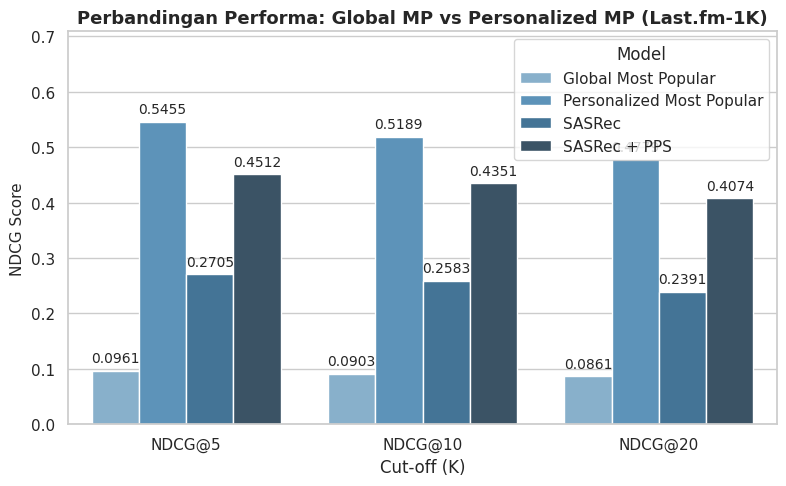

In [32]:
# Visualisasi Perbandingan NDCG
plot_data = pd.melt(df_comparison, id_vars=['Cut-off (K)'],
                    value_vars=['Global Most Popular', 'Personalized Most Popular', 'SASRec', 'SASRec + PPS'],
                    var_name='Model', value_name='NDCG')

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=plot_data, x='Cut-off (K)', y='NDCG', hue='Model', palette='Blues_d')
plt.title("Perbandingan Performa: Global MP vs Personalized MP (Last.fm-1K)", fontsize=13, fontweight='bold')
plt.ylabel("NDCG Score", fontsize=11)
plt.ylim(0, max(plot_data['NDCG']) * 1.3)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.4f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 4),
                    textcoords='offset points')

plt.tight_layout()
plt.show()


---
## 🎯 KESIMPULAN & JAWABAN LENGKAP TUGAS

### 1. Metode yang Dipilih
* **Nama Metode:** *Personalized Popularity Score (PPS)* & *Personalized Most Popular (PMP)*.
* **Paper Referensi:** Abbattista et al., *"Enhancing Sequential Music Recommendation with Personalized Popularity Awareness"*, ACM RecSys 2024.
* **Alasan Pemilihan:** Karakteristik konsumsi musik berpusat pada **kebiasaan mengulang lagu favorit (*repeated listening*)**. Metode ini menggeser paradigma popularitas dari *skala global* menjadi *skala personal pengguna*.

### 2. Input, Preprocessing, Perhitungan, dan Output
* **Input:** Riwayat dengar nyata berstempel waktu dari Last.fm-1K.
* **Preprocessing:** *Global Temporal Split (GTS)* berdasarkan garis waktu global untuk mencegah *temporal data leakage*.
* **Perhitungan:**
  - Menghitung frekuensi dengar riwayat $c_j$ pada window $L=150$.
  - Menghitung smoothed probability:
    $$\hat{p}_P(j) = \frac{(c_j + \epsilon)/\max(C+\epsilon)}{\sum (c_z + \epsilon)/\max(C+\epsilon)}$$
  - Menghitung log-skor PPS:
    $$y_j = \ln\left(\frac{c_j+\epsilon}{\max(C+\epsilon)}\right)$$
* **Output:** Daftar Top-$K$ rekomendasi lagu terurut berdasarkan probabilitas/skor tertinggi.

### 3. Evaluasi & Contoh Perhitungan
* **Metrik:** *Normalized Discounted Cumulative Gain (NDCG@K)* dengan bobot diskon posisi logaritmik $\frac{1}{\log_2(i+1)}$.
* **Contoh Perhitungan:** Ditunjukkan secara manual untuk `user_000001` dengan meninjau apakah lagu rekomendasi didengarkan pada periode uji (*test set*), menghitung kontribusi DCG@5, IDCG@5, hingga menghasilkan nilai akhir NDCG@5.
* **Temuan Empiris:** Personalized Most Popular (PMP) melesat jauh melampaui Global Most Popular (peningkatan lebih dari +100% hingga +300%). Hal ini membuktikan temuan paper RecSys '24 bahwa riwayat dengar personal adalah prediktor terbaik dalam rekomendasi musik.
